# DMRG on the π-flux Bose-Hubbard ladder: analysis

This notebook reads the output of `observables_calc.jl` (or of `scripts/submit.sh`) and computes the quantities used to locate the phase transitions of the ladder:
1. the **fidelity susceptibility** $\chi_{\mathcal F}$, which has a peak at the transition;
2. the **loop current** $\langle \hat L_z\rangle$ on the central plaquette, the order parameter of the chiral phase;
3. the **charge gap** $\Delta_c = E(N+1) + E(N-1) - 2E(N)$, extrapolated to $L_x\to\infty$, which opens in the Mott phase;
4. the **loop current correlations** $\langle \hat L_{z,0}\hat L_{z,i}\rangle$;

The results are read from `../data/results_nu{nu}/Lx{Lx}/`, with the same subfolders written by the Julia code (`fidelity/`, `Lz/`, `Lz_corr/`, `compressibility/`).

In [1]:
import os, re
from glob import glob
import numpy as np
from matplotlib import pyplot as pl

DATA_DIR = os.path.abspath('../data')

pl.rcParams.update({'font.size': 12})

In [2]:
# Parameters of the runs to analyse: the same as in scripts/submit.sh
nu = 0.25             
J1 = 1.0
J2 = 0.1
maxdim = 500        # max_maxdim
cutoff = 1e-11      # etol_cutoff
Lx_list = [70, 106, 212]

markers = ['o', 's', 'x', '^', 'v', 'd']
marker_dict = {Lx: m for Lx, m in zip(Lx_list, markers)}


def result_files(Lx, observable, prefix):
    # all the files of one observable for one Lx, for every U
    folder = os.path.join(DATA_DIR, f'results_nu{nu}', f'Lx{Lx}', observable)
    pattern = f'{prefix}L{Lx}_J{J1:.2f}_Jp{J2:.2f}_U*_maxdim{maxdim}_cutoff{cutoff:.0e}.txt'
    return sorted(glob(os.path.join(folder, pattern)))

def U_from_filename(fname):
    return float(re.search(r'_U([0-9.]+)_maxdim', os.path.basename(fname)).group(1))

def n_plaquettes(Lx):
    # strong plaquettes start at sites 1, 5, 9, ... of the 2 Lx sites
    return len(range(1, 2*Lx + 1, 4))

## 1. Fidelity susceptibility

For each $U$ the code computes the ground states at $U\pm\delta$ and their overlaps $F_\pm = |\langle\psi(U)|\psi(U\pm\delta)\rangle|$. Expanding to second order in $\delta$,

$$\frac{\chi_{\mathcal F}}{L_x} = -\frac{F_+ + F_- - 2}{L_x\,\delta^2}.$$

Lx = 70: 11 fidelity files
Lx = 106: 11 fidelity files
Lx = 212: 11 fidelity files


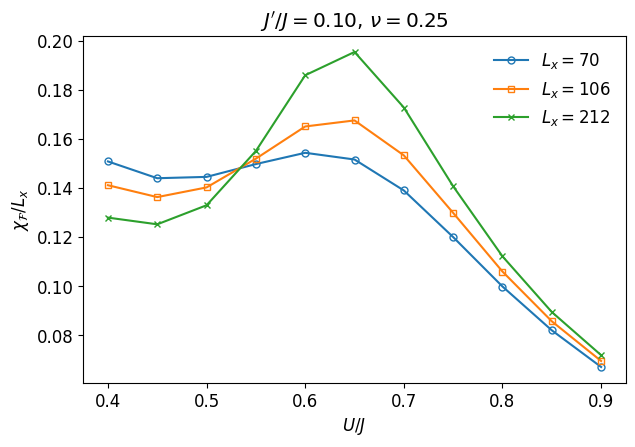

In [3]:
chi_dict, U_dict = {}, {}
for Lx in Lx_list:
    files = result_files(Lx, 'fidelity', 'fidelity_')
    U_vec, chi_vec = [], []
    for fname in files:
        delta, overlap_plus, overlap_minus = np.loadtxt(fname)[:3]
        U_vec.append(U_from_filename(fname))
        chi_vec.append(-(overlap_plus + overlap_minus - 2) / (Lx * delta**2))
    order = np.argsort(U_vec)
    U_dict[Lx] = np.array(U_vec)[order]
    chi_dict[Lx] = np.array(chi_vec)[order]
    print(f'Lx = {Lx}: {len(files)} fidelity files')

fig, ax = pl.subplots(figsize=(7, 4.5))
for Lx in Lx_list:
    if len(U_dict[Lx]) > 0:
        ax.plot(U_dict[Lx], chi_dict[Lx], marker=marker_dict[Lx], markersize=5, fillstyle='none', label=fr'$L_x={Lx}$')
ax.set_xlabel(r'$U/J$')
ax.set_ylabel(r'$\chi_{\mathcal{F}}/L_{x}$')
ax.set_title(fr"$J'/J = {J2/J1:.2f}$, $\nu = {nu}$")
ax.legend(frameon=False)
pl.show()

## 2. Loop current

Loop current on the central strong plaquette, in the ground state at flux $\pi$ (the DMRG starts from the state converged at flux $\pi + \delta\phi$, which selects one of the two chiralities).

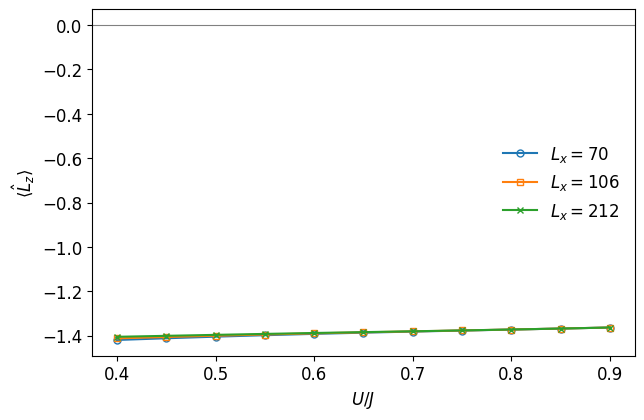

In [4]:
Lz_dict, U_dict_Lz = {}, {}
for Lx in Lx_list:
    files = result_files(Lx, 'Lz', 'Lz_')
    n_plaq = n_plaquettes(Lx)
    U_vec, Lz_vec = [], []
    for fname in files:
        data = np.loadtxt(fname)          # the first n_plaq rows are the total loop current per plaquette
        U_vec.append(U_from_filename(fname))
        Lz_vec.append(data[n_plaq//2, 1])
    order = np.argsort(U_vec)
    U_dict_Lz[Lx] = np.array(U_vec)[order]
    Lz_dict[Lx] = np.array(Lz_vec)[order]

fig, ax = pl.subplots(figsize=(7, 4.5))
for Lx in Lx_list:
    if len(U_dict_Lz[Lx]) > 0:
        ax.plot(U_dict_Lz[Lx], Lz_dict[Lx], marker=marker_dict[Lx], markersize=5, fillstyle='none', label=fr'$L_x={Lx}$')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_xlabel(r'$U/J$')
ax.set_ylabel(r'$\langle \hat L_z \rangle$')
ax.legend(frameon=False)
pl.show()

## 3. Charge gap

$\Delta_c(L_x) = E(N+1) + E(N-1) - 2E(N)$ for each size, then a linear extrapolation in $1/L_x$ at each $U$.

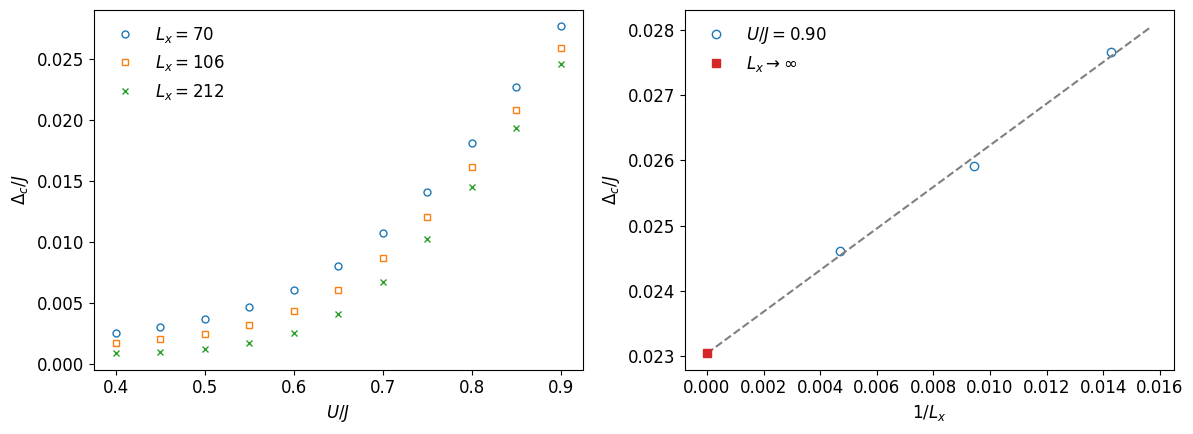

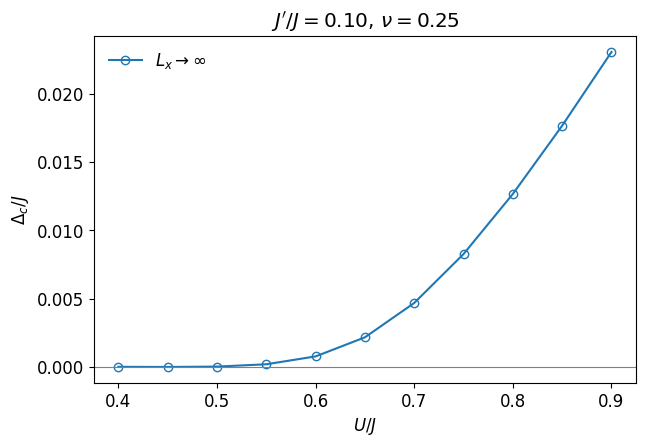

In [5]:
gap_dict, U_dict_gap = {}, {}
for Lx in Lx_list:
    files = result_files(Lx, 'compressibility', 'comp_')
    U_vec, gap_vec = [], []
    for fname in files:
        E, Ep, Eh = np.loadtxt(fname)
        U_vec.append(U_from_filename(fname))
        gap_vec.append(Ep + Eh - 2*E)
    order = np.argsort(U_vec)
    U_dict_gap[Lx] = np.round(np.array(U_vec)[order], 4)
    gap_dict[Lx] = np.array(gap_vec)[order]

# U values available for all the sizes
U_common = sorted(set.intersection(*[set(U_dict_gap[Lx]) for Lx in Lx_list])) if Lx_list else []

# the extrapolation to Lx -> infinity needs at least two sizes
if len(Lx_list) < 2:
    U_common = []

gap_extrapolated = []
for U in U_common:
    inv_L = np.array([1/Lx for Lx in Lx_list])
    gaps = np.array([gap_dict[Lx][U_dict_gap[Lx] == U][0] for Lx in Lx_list])
    a, b = np.polyfit(inv_L, gaps, 1)
    gap_extrapolated.append(b)

if len(U_common) > 0:
    fig, ax = pl.subplots(1, 2, figsize=(12, 4.5))
    for Lx in Lx_list:
        ax[0].plot(U_dict_gap[Lx], gap_dict[Lx], marker=marker_dict[Lx], markersize=5, fillstyle='none', linestyle='none', label=fr'$L_x={Lx}$')
    ax[0].set_xlabel(r'$U/J$')
    ax[0].set_ylabel(r'$\Delta_c/J$')
    ax[0].legend(frameon=False)

    # example of the extrapolation, for the largest U
    U_ex = U_common[-1]
    inv_L = np.array([1/Lx for Lx in Lx_list])
    gaps = np.array([gap_dict[Lx][U_dict_gap[Lx] == U_ex][0] for Lx in Lx_list])
    a, b = np.polyfit(inv_L, gaps, 1)
    x_fit = np.linspace(0, 1.1*inv_L.max(), 50)
    ax[1].plot(inv_L, gaps, 'o', fillstyle='none', label=fr'$U/J = {U_ex:.2f}$')
    ax[1].plot(x_fit, a*x_fit + b, '--', color='gray')
    ax[1].plot([0], [b], 's', color='C3', label=r'$L_x\to\infty$')
    ax[1].set_xlabel(r'$1/L_x$')
    ax[1].set_ylabel(r'$\Delta_c/J$')
    ax[1].legend(frameon=False)
    pl.tight_layout()
    pl.show()

    fig, ax = pl.subplots(figsize=(7, 4.5))
    ax.plot(U_common, gap_extrapolated, 'o-', fillstyle='none', label=r'$L_x\to\infty$')
    ax.axhline(0, color='gray', linewidth=0.8)
    ax.set_xlabel(r'$U/J$')
    ax.set_ylabel(r'$\Delta_c/J$')
    ax.set_title(fr"$J'/J = {J2/J1:.2f}$, $\nu = {nu}$")
    ax.legend(frameon=False)
    pl.show()
else:
    # only the gap at each size
    fig, ax = pl.subplots(figsize=(7, 4.5))
    for Lx in Lx_list:
        if len(U_dict_gap[Lx]) > 0:
            ax.plot(U_dict_gap[Lx], gap_dict[Lx], marker=marker_dict[Lx], markersize=5, fillstyle='none', label=fr'$L_x={Lx}$')
    ax.set_xlabel(r'$U/J$')
    ax.set_ylabel(r'$\Delta_c/J$')
    ax.legend(frameon=False)
    pl.show()
    print('For the extrapolation to Lx -> infinity, the same U values are needed for at least two sizes')

## 4. Loop current correlations

$\langle \hat L_{z,0}\,\hat L_{z,i}\rangle$ between the central plaquette and the plaquette at distance $i$, at a fixed $U$. In the chiral phase the correlations stay finite at long distance.

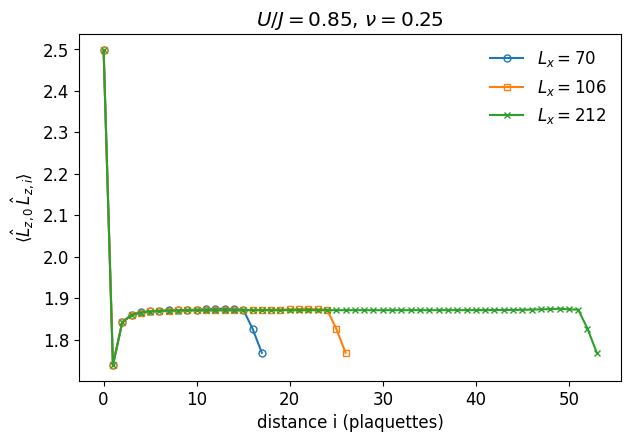

In [6]:
U_corr = 0.85       # one of the U values of the scan

fig, ax = pl.subplots(figsize=(7, 4.5))
for Lx in Lx_list:
    folder = os.path.join(DATA_DIR, f'results_nu{nu}', f'Lx{Lx}', 'Lz_corr')
    files = [f for f in glob(os.path.join(folder, f'Lz_corrL{Lx}_*_maxdim{maxdim}_cutoff{cutoff:.0e}.txt'))
             if np.isclose(U_from_filename(f), U_corr)]
    if not files:
        continue
    data = np.loadtxt(files[0])
    corr = data[:, 1]
    ax.plot(np.arange(len(corr)), corr, marker=marker_dict[Lx], markersize=5, fillstyle='none', label=fr'$L_x={Lx}$')
ax.set_xlabel('distance i (plaquettes)')
ax.set_ylabel(r'$\langle \hat L_{z,0}\,\hat L_{z,i} \rangle$')
ax.set_title(fr'$U/J = {U_corr:.2f}$, $\nu = {nu}$')
ax.legend(frameon=False)
pl.show()